# 01 — Tải và xác minh dữ liệu

Đây là notebook đầu tiên trong thứ tự chạy, thuộc phần chuẩn bị dữ liệu của bước 2 trong pipeline.md. Bước 1 của pipeline là chốt đề tài/phân công, không có chương trình cần chạy.

Logic tải nằm trong `src/datasets/download.py`; notebook chỉ gọi module và hiển thị ảnh. Chọn kernel đã cài requirements.txt, **Restart Kernel → Run All**. Cần Internet để đối chiếu nguồn, không cần GPU hoặc API key.

Giữ nguyên SHA-256 ZIP Kvasir và revision CVC-ClinicDB. File đúng nguồn được giữ, bổ sung file thiếu, dừng khi xung đột; không sửa nhãn hoặc resize file gốc. Chỉ manifest được cập nhật. Không chia tập ở notebook này.

Máy đã có dữ liệu và manifest đúng thì có thể bỏ qua bước tải khi làm tiếp. Sau notebook này mở **02_prepare_data.ipynb**.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT_OVERRIDE = None
start = Path(PROJECT_ROOT_OVERRIDE).resolve() if PROJECT_ROOT_OVERRIDE else Path.cwd().resolve()
project_root = next((p for p in (start, *start.parents)
                     if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy repo; điền PROJECT_ROOT_OVERRIDE.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.datasets.download import DatasetDownloader, DATASETS
downloader = DatasetDownloader(project_root)
print("Project root:", project_root)


Project root: D:\DHCN\HK5\DL\Medical-Image-Segmentation


## Tải/đối chiếu và ghi manifest

Kvasir đối chiếu ZIP chính thức; ClinicDB lấy metadata SHA-256 LFS từ revision đã khóa. Có thể cần chạy lại khi lỗi kết nối. Chỉ manifest được cập nhật; ảnh/mask gốc không bị resize hoặc sửa nhãn. Các split hiện có không bị thay đổi.


In [4]:
manifest = downloader.run()


Kvasir-SEG:   0%|          | 0.00/46.2M [00:00<?, ?B/s]

Đối chiếu Kvasir-SEG/images:   0%|          | 0/1000 [00:00<?, ?it/s]

Đối chiếu Kvasir-SEG/masks:   0%|          | 0/1000 [00:00<?, ?it/s]

Tạo file Kvasir-SEG: 0it [00:00, ?it/s]

Kvasir-SEG: thêm 0 file, giữ 2000 file khớp nguồn.


Kiểm tra Kvasir-SEG:   0%|          | 0/1000 [00:00<?, ?it/s]

Đối chiếu CVC-ClinicDB/Hugging Face:   0%|          | 0/1224 [00:00<?, ?it/s]

CVC-ClinicDB: thêm 0 file, giữ 1224 file khớp revision Hugging Face.


Kiểm tra CVC-ClinicDB:   0%|          | 0/612 [00:00<?, ?it/s]


Hoàn tất. Manifest: D:\DHCN\HK5\DL\Medical-Image-Segmentation\data\dataset_manifest.json
Dataset               Ảnh   Mask  Định dạng
Kvasir-SEG           1000   1000       .jpg
  Mask có mức xám trung gian: 1000
CVC-ClinicDB          612    612       .png
  Mask có mức xám trung gian: 138
Dữ liệu sẵn sàng. Chưa tạo split và chưa huấn luyện mô hình.


## Xem ảnh, mask và overlay

Mỗi bộ xem một ảnh để kiểm tra vị trí nhãn. Mask hiển thị dùng ngưỡng >127; hình không phải dự đoán của mô hình và không thay đổi dữ liệu nguồn.


Kvasir-SEG: cju0qkwl35piu0993l0dewei2.jpg | Ảnh RGB — mask — overlay


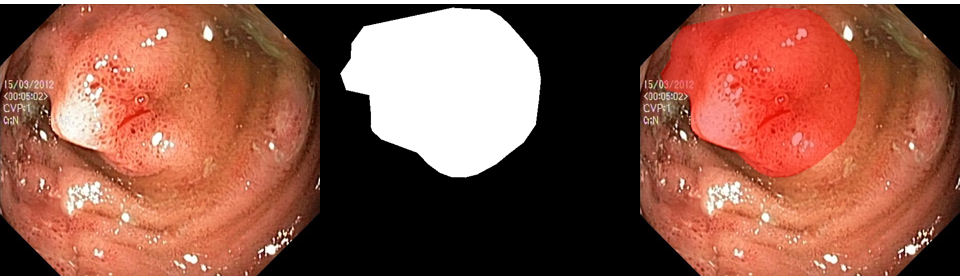

CVC-ClinicDB: 1.png | Ảnh RGB — mask — overlay


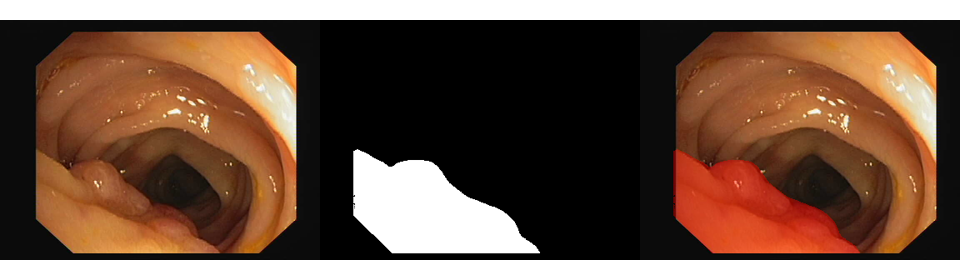

In [3]:
from PIL import Image
from IPython.display import display

for spec in DATASETS:
    folder = downloader.data_dir / spec['name']
    image_path = sorted((folder / 'images').glob('*' + spec['extension']))[0]
    mask_path = folder / 'masks' / image_path.name
    with Image.open(image_path) as source_image, Image.open(mask_path) as source_mask:
        image = source_image.convert('RGB')
        mask = source_mask.convert('L').point(lambda value: 255 if value > 127 else 0)
        red = Image.new('RGB', image.size, (255, 0, 0))
        overlay = Image.composite(Image.blend(image, red, 0.4), image, mask)
        panels = [image, mask.convert('RGB'), overlay]
        canvas = Image.new('RGB', (320 * 3, 280), 'white')
        for index, panel in enumerate(panels):
            panel.thumbnail((320, 280))
            canvas.paste(panel, (index * 320 + (320 - panel.width) // 2, (280 - panel.height) // 2))
        print(f"{spec['name']}: {image_path.name} | Ảnh RGB — mask — overlay")
        display(canvas)

# Tiếp theo: mở notebooks/02_prepare_data.ipynb.
